# LSRSNN на google speech commands

## Загрузка датасета
Гружу с kaggle версию 2017 года google speech commands, 30 различных классов аудио

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("neehakurelli/google-speech-commands")

print("Path to dataset files:", path)

100%|██████████| 1.38G/1.38G [00:16<00:00, 88.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/neehakurelli/google-speech-commands/versions/1


## Создание мел спектрограмм из аудио и создание датасета

В данном коде исходим из предположения, что входами модели будет каждый пиксель спектрограммы, а не каждый отдельно взятый канал

In [2]:
import os
import random
from dataclasses import dataclass

import numpy as np

import librosa
import librosa.display
import soundfile as sf
import torchaudio
from IPython.display import Audio

from sklearn.model_selection import train_test_split
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize, LinearSegmentedColormap

import networkx as nx


In [3]:
DATA_PATH = "/root/.cache/kagglehub/datasets/neehakurelli/google-speech-commands/versions/1"

# Hyperparameters
SAMPLE_RATE = 16000
DURATION = 1.0
N_MELS = 128
N_FFT = 400

def load_audio(file_path, target_sr=SAMPLE_RATE, duration=DURATION):
    """Load and preprocess audio file"""
    audio, sr = librosa.load(file_path, sr=target_sr, duration=duration)
    audio = librosa.util.fix_length(audio, size=int(target_sr * duration))
    return audio

def extract_features(file_path):
    """Extract mel spectrogram features"""
    audio = load_audio(file_path)
    mel_spec = librosa.feature.melspectrogram(y=audio, sr=SAMPLE_RATE, n_mels=N_MELS, n_fft=N_FFT)
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
    return mel_spec_db

def create_dataset(data_path):
    """Load and extract features from the dataset"""
    X, y = [], []
    all_items = sorted(os.listdir(data_path))
    classes = [item for item in all_items
               if os.path.isdir(os.path.join(data_path, item))
               and item != "_background_noise_"]

    label_map = {label: idx for idx, label in enumerate(classes)}

    for label in classes:
        folder = os.path.join(data_path, label)
        for file_name in os.listdir(folder):
            file_path = os.path.join(folder, file_name)
            if file_path.endswith(('.wav', '.mp3', '.flac')):
                features = extract_features(file_path)
                X.append(features)
                y.append(label_map[label])

    return np.array(X), np.array(y), label_map

# Load dataset
X, y, label_map = create_dataset(DATA_PATH)

## Разделение датасета на train и test
В kaggle версии представлены отдельные списки файлов, которые можно использовать в качестве тестовой и валидационной выборки, но здесь они делятся сами

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Аугментация изображений



In [5]:
def _ensure_3d(x: torch.Tensor) -> torch.Tensor:
    # HxW -> 1xHxW
    if x.dim() == 2:
        return x.unsqueeze(0)
    if x.dim() == 3:
        return x
    raise ValueError("Expected 2D or 3D tensor (H x W or C x H x W).")

class Identity:
    def __call__(self, x, other=None):
        return x

@dataclass
class TimeMask:
    """Аугментация по времени (вертикальные линии)."""

    enabled: bool = True
    num_masks: int = 2
    max_width_frac: float = 0.12
    fill: str = "min"  # "min" or "zero"

    def __call__(self, x: torch.Tensor, other=None) -> torch.Tensor:
        if not self.enabled:
            return x
        x = _ensure_3d(x)
        C, H, W = x.shape
        fill_value = x.min() if self.fill == "min" else torch.tensor(0.0, device=x.device, dtype=x.dtype)

        max_w = max(1, int(W * self.max_width_frac))
        for _ in range(self.num_masks):
            w = random.randint(1, max_w)
            t0 = random.randint(0, max(0, W - w))
            x[:, :, t0:t0+w] = fill_value
        return x

@dataclass
class FreqMask:
    """Аугментация по частоте (горизонтальные линии)."""
    enabled: bool = True
    num_masks: int = 2
    max_width_frac: float = 0.12
    fill: str = "min"

    def __call__(self, x: torch.Tensor, other=None) -> torch.Tensor:
        if not self.enabled:
            return x
        x = _ensure_3d(x)
        C, H, W = x.shape
        fill_value = x.min() if self.fill == "min" else torch.tensor(0.0, device=x.device, dtype=x.dtype)

        max_h = max(1, int(H * self.max_width_frac))
        for _ in range(self.num_masks):
            h = random.randint(1, max_h)
            f0 = random.randint(0, max(0, H - h))
            x[:, f0:f0+h, :] = fill_value
        return x

@dataclass
class GaussianNoise:
    """Гауссов шум добавляет смещения ко всем пикселям."""
    enabled: bool = True
    std: float = 0.02

    def __call__(self, x: torch.Tensor, other=None) -> torch.Tensor:
        if not self.enabled or self.std <= 0:
            return x
        x = _ensure_3d(x)
        return x + torch.randn_like(x) * self.std

@dataclass
class SaltPepperPixelwise:
    """Аугментация соль и перец."""

    enabled: bool = True
    p: float = 0.01                 # доля пикселей, которые заменим
    salt_vs_pepper: float = 0.5     # доля "salt" среди зашумленных
    salt_value: str = "max"         # значение для соли
    pepper_value: str = "min"       # значение для перца
    salt_fixed: float = 1.0
    pepper_fixed: float = 0.0

    def __call__(self, x: torch.Tensor, other=None) -> torch.Tensor:
        if not self.enabled or self.p <= 0:
            return x
        x = _ensure_3d(x)
        # работаем по всем каналам одинаково, по пикселям HxW
        C, H, W = x.shape

        # маска "где шумим"
        noise_mask = (torch.rand((H, W), device=x.device) < self.p)

        # среди этих пикселей — какие salt
        salt_mask = noise_mask & (torch.rand((H, W), device=x.device) < self.salt_vs_pepper)
        pepper_mask = noise_mask & (~salt_mask)

        # значения salt/pepper
        salt_val = x.max() if self.salt_value == "max" else torch.tensor(self.salt_fixed, device=x.device, dtype=x.dtype)
        pepper_val = x.min() if self.pepper_value == "min" else torch.tensor(self.pepper_fixed, device=x.device, dtype=x.dtype)

        # применяем ко всем каналам
        for c in range(C):
            xc = x[c]
            xc[salt_mask] = salt_val
            xc[pepper_mask] = pepper_val
            x[c] = xc
        return x

class SpectrogramAugment:
    """Класс для сбора всех аугментаций."""

    def __init__(self,
                 time_mask=TimeMask(),
                 freq_mask=FreqMask(),
                 gauss=GaussianNoise(),
                 sp=SaltPepperPixelwise(),
                 prob: float = 0.95):
        self.time_mask = time_mask
        self.freq_mask = freq_mask
        self.gauss = gauss
        self.sp = sp
        self.prob = prob

    def __call__(self, x: torch.Tensor):
        # x: HxW or CxHxW
        if self.prob < 1.0 and random.random() > self.prob:
            return _ensure_3d(x)

        x = _ensure_3d(x)
        x = self.freq_mask(x)
        x = self.time_mask(x)
        x = self.gauss(x)
        x = self.sp(x)

        return x


In [6]:
# 1) Конфигурация аугментаций

train_transform = SpectrogramAugment(
    prob=0.01,  # вероятность применить аугментации on-the-fly
    time_mask=TimeMask(enabled=False, num_masks=2, max_width_frac=0.12, fill="min"),
    freq_mask=FreqMask(enabled=False, num_masks=2, max_width_frac=0.12, fill="min"),
    gauss=GaussianNoise(enabled=False, std=0.02),
    sp=SaltPepperPixelwise(enabled=True, p=0.01, salt_vs_pepper=0.5),
)

test_transform = None  # тест обычно без аугментаций


# 2) OFFLINE-аугментация

USE_OFFLINE_AUG = True    # Флаг увелечения train
AUGMENT_RATIO = 0.5         # доля train, которую продублируем с аугментацией

if USE_OFFLINE_AUG:
    # Для оффлайна лучше гарантировать применение трансформа: prob=1.0
    offline_transform = SpectrogramAugment(
        prob=1.0,
        time_mask=train_transform.time_mask,
        freq_mask=train_transform.freq_mask,
        gauss=train_transform.gauss,
        sp=train_transform.sp,
    )

    X_list = [X_train]
    y_list = [y_train]

    n = len(X_train)
    m = int(n * AUGMENT_RATIO)

    idx = np.random.choice(n, size=m, replace=False)

    X_aug = []
    y_aug = []
    for i in idx:
        # ожидаем, что X_train[i] это HxW (numpy или torch)
        x = X_train[i]
        if not torch.is_tensor(x):
            x = torch.tensor(x, dtype=torch.float32)

        x_t = offline_transform(x)          # -> [1,H,W] torch
        X_aug.append(x_t.squeeze(0).cpu().numpy())  # обратно в HxW для согласованности
        y_aug.append(int(y_train[i]))

    X_aug = np.stack(X_aug, axis=0)
    y_aug = np.array(y_aug, dtype=np.int64)

    X_train = np.concatenate([X_train, X_aug], axis=0)
    y_train = np.concatenate([y_train, y_aug], axis=0)

    print(f"Offline augmentation enabled: train size {n} -> {len(X_train)}")


# 3) Датасеты и DataLoader'ы


class SimpleSpectrogramDataset(Dataset):
    """Датасет для спектрограмм."""

    def __init__(self, X, y, transform=None):
        # X: numpy array [N, H, W]  expected
        self.X = torch.tensor(X, dtype=torch.float32)  # keep as [N, H, W]
        self.y = torch.tensor(y, dtype=torch.long)
        self.transform = transform

    def __getitem__(self, idx):
        spec = self.X[idx]             # [H, W]
        if self.transform is not None:
            # transform принимает HxW or CxHxW -> возвращает HxW or CxHxW
            out = self.transform(spec)  # HxW (или CxHxW)
            # гарантируем, что модель получит [1, H, W] shape (как раньше)
            if out.dim() == 2:
                spec = out.unsqueeze(0)      # [1, H, W]
            elif out.dim() == 3:
                spec = out                  # [C, H, W]
            else:
                raise ValueError("Unexpected transform output dims")
        else:
            # если нет трансформации — приводим к [1, H, W]
            spec = spec.unsqueeze(0)

        return spec, self.y[idx]

    def __len__(self):
        return len(self.y)

train_dataset = SimpleSpectrogramDataset(X_train, y_train, transform=train_transform)

test_dataset  = SimpleSpectrogramDataset(X_test,  y_test,  transform=test_transform)

batch_size = 64
num_workers = 2
pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
    num_workers=num_workers,
    pin_memory=pin_memory,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    drop_last=False,
    num_workers=num_workers,
    pin_memory=pin_memory,
)

# 4) Проверка формы

xb, yb = next(iter(train_loader))
print("train batch x:", xb.shape, xb.dtype)  # ожидаем [B, 1, H, W]
print("train batch y:", yb.shape, yb.dtype)

Offline augmentation enabled: train size 51776 -> 77664
train batch x: torch.Size([64, 1, 128, 32]) torch.float32
train batch y: torch.Size([64]) torch.int64


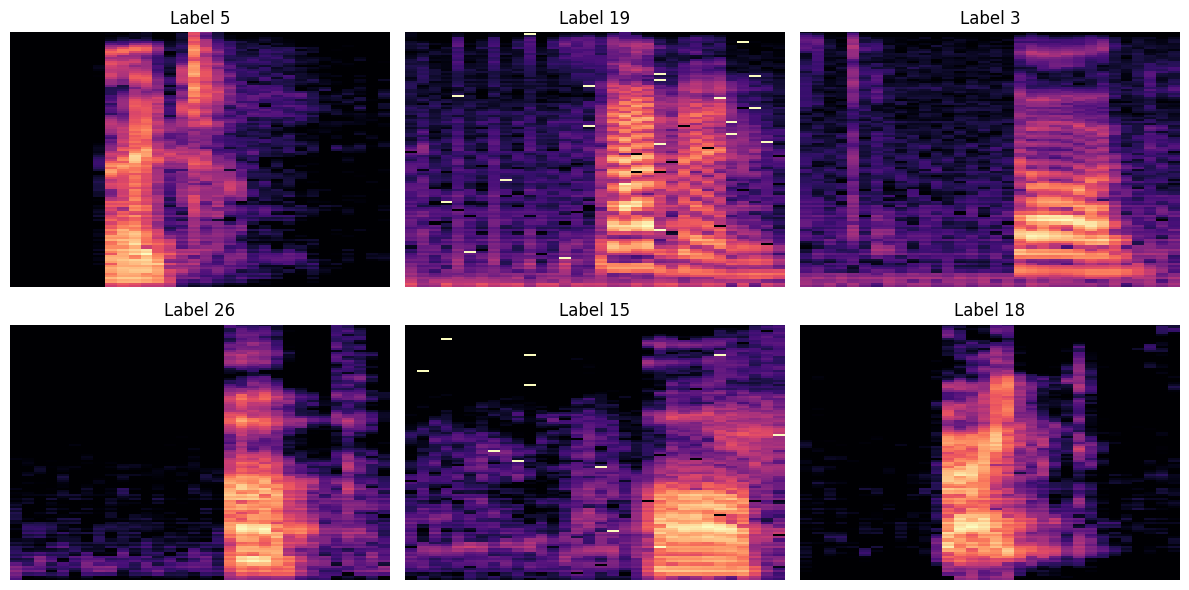

In [7]:
def show_batch(batch, n=6):
    images, labels = batch
    images = images[:n].squeeze(1).cpu().numpy()  # [n, H, W]

    plt.figure(figsize=(12, 6))
    for i in range(n):
        plt.subplot(2, n//2, i+1)
        plt.imshow(images[i], cmap='magma', origin='lower', aspect='auto')
        plt.title(f"Label {labels[i].item()}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()

batch = next(iter(train_loader))
show_batch(batch)


**Классы**

In [8]:
label_map = {0: 'bed', 1: 'bird', 2: 'cat', 3: 'dog', 4: 'down', 5: 'eight',
             6: 'five', 7: 'four', 8: 'go', 9: 'happy', 10: 'house', 11: 'left',
             12: 'marvin', 13: 'nine', 14: 'no', 15: 'off', 16: 'on', 17: 'one',
             18: 'right', 19: 'seven', 20: 'sheila', 21: 'six', 22: 'stop',
             23: 'three', 24: 'tree', 25: 'two', 26: 'up', 27: 'wow', 28: 'yes', 29: 'zero'}

## Суррогатная функция

In [9]:
class MultiGaussianSurrogate(torch.autograd.Function):

    @staticmethod
    def forward(ctx, input, h, l, s):
        ctx.save_for_backward(input)
        ctx.h = h
        ctx.l = l
        ctx.s = s
        return (input > 0).float()

    @staticmethod
    def backward(ctx, grad_output):
        input,  = ctx.saved_tensors
        h = ctx.h
        l = ctx.l
        s = ctx.s

        term1 = (1+h) * torch.exp(-(input/l)**2 / 2) / (np.sqrt(2*np.pi)*l)
        term2 = h * torch.exp(-((input-l)/(s*l))**2 / 2) / (np.sqrt(2*np.pi)*(s*l))
        term3 = h * torch.exp(-((input+l)/(s*l))**2 / 2) / (np.sqrt(2*np.pi)*(s*l))
        grad = term1 - term2 - term3
        return grad_output * grad, None, None, None

## **Модель LIF нейрона**

Реализация LIF нейрона с бимодальным/нормальным распределением временных констант tau.

В LIF нейрон в spiking jelly из коробки не смог добавить обучаемость tau, поэтому рабочая версия на torch.

In [10]:
from scipy.stats import truncnorm

class BimodalLIFLayer(nn.Module):
    """LIF-нейрон с обучаемым параметрем tau."""

    def __init__(self, size, tau_short=(0, 20), tau_long=(80,100), fraction_long=0.5, v_th=1.0, dt=1.0):
        super().__init__()

        # Закоменчена реализация бимодального распределения #
        # __________________________________________________#

        # N_long = int(size * fraction_long)
        # N_short = size - N_long

        # tau_m_vals = np.concatenate([
        #     np.random.uniform(*tau_short, N_short),
        #     np.random.uniform(*tau_long, N_long)
        # ])

        # __________________________________________________#


        # Нормальное распределение
        a, b = (0 - 50) / 15, (100 - 50) / 15
        tau_m_vals = truncnorm.rvs(a, b, loc=50, scale=15, size=size).astype(np.float32)

        # tau обучаемый параметр!
        self.tau_m = nn.Parameter(torch.tensor(tau_m_vals, dtype=torch.float32), requires_grad=True)

        self.v_th = v_th
        self.dt = dt
        self.size = size

    def forward(self, x, v, z):
        rho = torch.exp(-self.dt/self.tau_m.to(x.device))
        v_new = rho * v + (1 - rho) * x - self.v_th * z
        return v_new

    def reset(self, batch_size):
        return torch.zeros(batch_size, self.size)

## **Реализация модели.**

1_to_3_to_1

backpropagation задавать отдельно не нужно, forward сохраняет всю информацию для него сам.

Реализация на torch, но в spiking jelly достаточно похожая среда

In [13]:
class SpikingConvBlock(nn.Module):
    def __init__(self, cin, cout, hw, use_bn=True, dt=1.0, v_th=1.0, fraction_long=0.5):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=not use_bn)
        self.bn   = nn.BatchNorm2d(cout) if use_bn else nn.Identity()
        self.pool = nn.AvgPool2d(2)
        self.v_th = v_th

        h, w = hw if isinstance(hw, (tuple, list)) else (hw, hw)
        self.feat_size = cout * h * w

        self.lif = BimodalLIFLayer(
            size=self.feat_size,
            fraction_long=fraction_long,
            dt=dt,
            v_th=v_th,
        )

    def init_state(self, batch_size, device, dtype=torch.float32):
        return {
            'v': torch.zeros(batch_size, self.feat_size, device=device, dtype=dtype),
            'z': torch.zeros(batch_size, self.feat_size, device=device, dtype=dtype),
        }

    def forward_step(self, x, state, spike_params):
        hs, ls, ss = spike_params
        y     = self.bn(self.conv(x))
        yflat = y.flatten(1)

        v_new = self.lif(yflat, state['v'], state['z'])
        z_new = MultiGaussianSurrogate.apply(v_new - self.v_th, hs, ls, ss)

        y_out = self.pool(z_new.view_as(y))
        state['v'] = v_new
        state['z'] = z_new
        return y_out, state


class SpikingConvFrontEnd(nn.Module):
    def __init__(self, in_ch=1, conv_channels=(32, 64, 128), use_bn=True,
                 hw=64, dt=1.0, v_th=1.0, fraction_long=0.5,
                 spike_params=(0.15, 0.5, 6)):
        super().__init__()
        c1, c2, c3 = conv_channels
        h, w = hw if isinstance(hw, (tuple, list)) else (hw, hw)

        self.blocks = nn.ModuleList([
            SpikingConvBlock(in_ch, c1, (h,    w   ), use_bn, dt, v_th, fraction_long),
            SpikingConvBlock(c1,    c2, (h//2, w//2), use_bn, dt, v_th, fraction_long),
            SpikingConvBlock(c2,    c3, (h//4, w//4), use_bn, dt, v_th, fraction_long),
        ])
        self.spike_params = spike_params

    def init_state(self, batch_size, device, dtype=torch.float32):
        return [blk.init_state(batch_size, device, dtype) for blk in self.blocks]

    def forward_step(self, x, state, spike_params):
        for i, blk in enumerate(self.blocks):
            x, state[i] = blk.forward_step(x, state[i], spike_params)
        return x, state

    def forward(self, x):
        B = x.shape[0]
        state = self.init_state(B, x.device, x.dtype)
        out, _ = self.forward_step(x, state, self.spike_params)
        return out

In [26]:
class DeepBifurcatedReservoirSNN(nn.Module):
    """
    CNN → w_in → Res1 ──┬── Res2 ──┐
                         ├── Res3 ──┼── w_merge → Res5 → w_out → output
                         └── Res4 ──┘
    """
    def __init__(
        self,
        input_size: int,
        res1_size: int,            # общий первый резервуар
        res_branch_size: int,      # размер каждой из трёх параллельных веток
        res5_size: int,            # финальный объединяющий резервуар
        output_size: int,
        fraction_long: float = 0.5,
        dt: float = 1.0,
        v_th: float = 1.0,
        spike_params=(0.15, 0.5, 6),
        use_cnn: bool = True,
        cnn_in_ch: int = 1,
        cnn_channels=(32, 64, 128),
        cnn_use_bn: bool = True,
        cnn_hw=64,
    ):
        super().__init__()

        self.dt             = dt
        self.v_th           = v_th
        self.spike_params   = spike_params
        self.use_cnn        = use_cnn
        self.cnn_in_ch      = cnn_in_ch
        self.res1_size      = res1_size
        self.res_branch_size = res_branch_size
        self.res5_size      = res5_size

        # ── CNN front-end ───────────────────────────────────────────────────
        if self.use_cnn:
            h_cnn, w_cnn = (cnn_hw, cnn_hw) if isinstance(cnn_hw, int) else cnn_hw
            self.cnn_h = h_cnn
            self.cnn_w = w_cnn
            self.cnn = SpikingConvFrontEnd(
                in_ch=cnn_in_ch,
                conv_channels=cnn_channels,
                use_bn=cnn_use_bn,
                hw=(h_cnn, w_cnn),
                dt=dt, v_th=v_th,
                fraction_long=fraction_long,
            )
            cnn_feat_dim = cnn_channels[-1] * (h_cnn // 8) * (w_cnn // 8)
            self.w_in = nn.Linear(cnn_feat_dim, res1_size, bias=False)
        else:
            self.cnn = None
            self.cnn_h = self.cnn_w = None
            self.w_in = nn.Linear(input_size, res1_size, bias=False)

        # ── Res1 — общий первый резервуар ──────────────────────────────────
        self.lif1  = BimodalLIFLayer(res1_size, fraction_long=fraction_long, dt=dt, v_th=v_th)
        self.wrec1 = nn.Linear(res1_size, res1_size, bias=False)

        # ── Три параллельные ветки (Res2, Res3, Res4) ──────────────────────
        # Каждая получает z1 через свою проекцию + свою рекуррентность
        self.wff2  = nn.Linear(res1_size, res_branch_size, bias=False)
        self.lif2  = BimodalLIFLayer(res_branch_size, fraction_long=fraction_long, dt=dt, v_th=v_th)
        self.wrec2 = nn.Linear(res_branch_size, res_branch_size, bias=False)

        self.wff3  = nn.Linear(res1_size, res_branch_size, bias=False)
        self.lif3  = BimodalLIFLayer(res_branch_size, fraction_long=fraction_long, dt=dt, v_th=v_th)
        self.wrec3 = nn.Linear(res_branch_size, res_branch_size, bias=False)

        self.wff4  = nn.Linear(res1_size, res_branch_size, bias=False)
        self.lif4  = BimodalLIFLayer(res_branch_size, fraction_long=fraction_long, dt=dt, v_th=v_th)
        self.wrec4 = nn.Linear(res_branch_size, res_branch_size, bias=False)

        # ── Схлопывание: concat(z2, z3, z4) → Res5 ────────────────────────
        self.w_merge = nn.Linear(res_branch_size * 3, res5_size, bias=False)
        self.lif5    = BimodalLIFLayer(res5_size, fraction_long=fraction_long, dt=dt, v_th=v_th)
        self.wrec5   = nn.Linear(res5_size, res5_size, bias=False)

        # ── Выход ──────────────────────────────────────────────────────────
        self.w_out = nn.Linear(res5_size, output_size, bias=False)

        # ── Инициализация весов ─────────────────────────────────────────────
        for layer in [self.w_in,
                      self.wrec1,
                      self.wff2, self.wrec2,
                      self.wff3, self.wrec3,
                      self.wff4, self.wrec4,
                      self.w_merge, self.wrec5]:
            nn.init.uniform_(layer.weight, -0.5, 0.5)
        nn.init.uniform_(self.w_out.weight, -0.5, 0.5)

    def forward(self, x_seq):    # [T, B, Fin]
        T, B, Fin = x_seq.shape
        device, dtype = x_seq.device, x_seq.dtype
        h_s, l_s, s_s = self.spike_params

        # ── CNN ────────────────────────────────────────────────────────────
        if self.use_cnn:
            x_mean = x_seq.mean(dim=0)                                   # [B, Fin]
            x_img  = x_mean.view(B, self.cnn_in_ch, self.cnn_h, self.cnn_w)
            feat   = self.cnn(x_img)                                     # [B, C, h, w]
            x_proj = self.w_in(feat.flatten(1))                          # [B, res1_size]
            x_proj = x_proj.unsqueeze(0).expand(T, -1, -1)              # [T, B, res1_size]
        else:
            x_proj = self.w_in(x_seq)                                    # [T, B, res1_size]

        # ── Инициализация состояний ─────────────────────────────────────────
        def zeros(*shape):
            return torch.zeros(*shape, device=device, dtype=dtype)

        v1, z1 = zeros(B, self.res1_size),       zeros(B, self.res1_size)
        v2, z2 = zeros(B, self.res_branch_size),  zeros(B, self.res_branch_size)
        v3, z3 = zeros(B, self.res_branch_size),  zeros(B, self.res_branch_size)
        v4, z4 = zeros(B, self.res_branch_size),  zeros(B, self.res_branch_size)
        v5, z5 = zeros(B, self.res5_size),        zeros(B, self.res5_size)

        outputs = []
        # Счётчики — сбрасываем при каждом forward
        sc = {'res1': 0.0, 'res2': 0.0, 'res3': 0.0, 'res4': 0.0, 'res5': 0.0}

        for t in range(T):
            x1 = x_proj[t] + self.wrec1(z1)
            v1 = self.lif1(x1, v1, z1)
            z1 = MultiGaussianSurrogate.apply(v1 - self.v_th, h_s, l_s, s_s)
            sc['res1'] += z1.detach().mean().item()   # среднее по нейронам и батчу

            x2 = self.wff2(z1) + self.wrec2(z2)
            v2 = self.lif2(x2, v2, z2)
            z2 = MultiGaussianSurrogate.apply(v2 - self.v_th, h_s, l_s, s_s)
            sc['res2'] += z2.detach().mean().item()

            x3 = self.wff3(z1) + self.wrec3(z3)
            v3 = self.lif3(x3, v3, z3)
            z3 = MultiGaussianSurrogate.apply(v3 - self.v_th, h_s, l_s, s_s)
            sc['res3'] += z3.detach().mean().item()

            x4 = self.wff4(z1) + self.wrec4(z4)
            v4 = self.lif4(x4, v4, z4)
            z4 = MultiGaussianSurrogate.apply(v4 - self.v_th, h_s, l_s, s_s)
            sc['res4'] += z4.detach().mean().item()

            merged = torch.cat([z2, z3, z4], dim=1)
            x5 = self.w_merge(merged) + self.wrec5(z5)
            v5 = self.lif5(x5, v5, z5)
            z5 = MultiGaussianSurrogate.apply(v5 - self.v_th, h_s, l_s, s_s)
            sc['res5'] += z5.detach().mean().item()

            outputs.append(self.w_out(z5))

        # Нормируем на T → firing rate: доля активаций на шаг
        self.last_firing_rates = {k: v / T for k, v in sc.items()}

        return torch.stack(outputs, dim=0)

In [15]:
print(len(train_dataset))

77664


## rate кодирование
В моей реализации сразу задаётся верхнее значение вероятности

In [16]:
def rate_code(
    x: torch.Tensor,
    time_steps: int,
    eps: float = 1e-6, # защита от деления на ~0 при нормализации
    p_max: float = 0.8, # верхняя граница вероятности спайка (контроль плотности)
    gamma: float = 1.0 # p = p**gamma (gamma>1 разрежает спайки, gamma<1 уплотняет)
):

    if x.dim() > 2:
        x = x.view(x.size(0), -1)  # [B, F]

    # per-sample min-max normalization
    x_min = x.amin(dim=1, keepdim=True)
    x_max = x.amax(dim=1, keepdim=True)
    denom = (x_max - x_min).clamp_min(eps)
    p = (x - x_min) / denom

    # контролируем насыщение/разреженность
    if gamma != 1.0:
        p = p.clamp(0.0, 1.0).pow(gamma)
    else:
        p = p.clamp(0.0, 1.0)

    if p_max is not None:
        p = p.clamp_max(p_max)

    p = p.detach()

    # sample Bernoulli spikes over time
    # создаём [T, B, F] вероятности
    probs = p.unsqueeze(0).expand(time_steps, -1, -1)

    spikes = (torch.rand(time_steps, *p.shape, device=x.device, dtype=p.dtype) < probs).to(torch.float32)
    return spikes

## **Задание модели и гиперпараметров.**

In [27]:
time_steps = 20
input_size = 64 * 64 # входной слой
hidden_size = 1000 # рекуррентный слой
output_size = 30 # выходной слой - кол-во классов
learning_rate = 2e-3
epochs = 50

In [28]:
import torch.nn.functional as F

# model = LSRSNN(input_size=input_size, hidden_size=hidden_size, output_size=output_size, fraction_long=0.5)
device = torch.device('cuda')
model = DeepBifurcatedReservoirSNN(
    input_size=128 * 32,
    res1_size=512,           # общий Res1
    res_branch_size=256,     # Res2, Res3, Res4 — каждая по 256
    res5_size=256,           # объединяющий Res5
    output_size=30,
    fraction_long=0.5,
    dt=1.0,
    v_th=1.0,
    spike_params=(0.15, 0.5, 6),
    use_cnn=True,
    cnn_in_ch=1,
    cnn_channels=(32, 64, 128),
    cnn_use_bn=True,
    cnn_hw=(128, 32),        # ← прямоугольный спектрограмм
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
model.to(device)

loss_history = []
accuracy_history = []

In [19]:
# print(model.w_in.weight)
# tau_before = model.hidden.tau_m.detach().cpu().numpy().copy()
# w_in_before = model.w_in.weight.detach().cpu().numpy().copy()
# w_out_before = model.w_out.weight.detach().cpu().numpy().copy()
# w_rec_before = model.w_rec.weight.detach().cpu().numpy().copy()
# print(np.average(w_in_before))
# print(np.average(w_out_before))
# print(np.average(w_rec_before))

Parameter containing:
tensor([[-0.2281,  0.1453,  0.0310,  ...,  0.0873,  0.1772,  0.2176],
        [ 0.3809,  0.2347,  0.2601,  ...,  0.2044, -0.1935,  0.1988],
        [-0.2605, -0.4871,  0.0327,  ..., -0.1867,  0.3107,  0.3053],
        ...,
        [ 0.0158,  0.4026, -0.4153,  ...,  0.0592,  0.4155,  0.1862],
        [ 0.1069, -0.0422, -0.1976,  ...,  0.0795,  0.2351,  0.3898],
        [ 0.2509, -0.4152, -0.2437,  ..., -0.3291, -0.0386, -0.0632]],
       device='cuda:0', requires_grad=True)


AttributeError: 'DeepBifurcatedReservoirSNN' object has no attribute 'hidden'

In [ ]:
print(device)

In [20]:
# neuron_activations = []  # список средних активаций по эпохам
# test_spike_history = []  # сырые спайки для анализа
test_loss_history = []
test_accuracy_history = []
# epoch_v_history = []
# epoch_tau = []

In [29]:
TIMESTEPS     = 20
LEARNING_RATE = 2e-3
EPOCHS        = 50
LOG_EVERY     = 1

In [30]:
train_loss_history = []
train_acc_history  = []
test_loss_history  = []
test_acc_history   = []

# ── Вспомогательная функция оценки ─────────────────────────────────────────
def run_epoch(loader, train: bool):
    total_loss, correct, count = 0.0, 0, 0
    # Накопители для firing rates по слоям
    fr_acc = {'res1': 0.0, 'res2': 0.0, 'res3': 0.0, 'res4': 0.0, 'res5': 0.0}
    n_batches = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device).long()

        images_flat = images.squeeze(1).flatten(1)
        spikes = rate_code(images_flat, TIMESTEPS, p_max=0.9, gamma=1.5)

        if train:
            optimizer.zero_grad()

        outputs = model(spikes)  # внутри сохраняется last_firing_rates

        # Забираем firing rates после каждого батча
        for k in fr_acc:
            fr_acc[k] += model.last_firing_rates[k]
        n_batches += 1

        log_probs = F.log_softmax(outputs, dim=-1)
        summed = torch.logsumexp(log_probs, dim=0)
        loss = F.nll_loss(summed, labels)

        if train:
            loss.backward()
            for name, param in model.named_parameters():
                if param.grad is not None and "taum" not in name:
                    param.data.clamp_(-10.0, 10.0)
            optimizer.step()

        total_loss += loss.item()
        correct += (summed.argmax(dim=1) == labels).sum().item()
        count += labels.size(0)

    # Средний firing rate за эпоху
    avg_fr = {k: v / n_batches for k, v in fr_acc.items()}
    return total_loss / len(loader), correct / count, avg_fr

# ── Основной цикл ────────────────────────────────────────────────────────────
for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss, train_acc, train_fr = run_epoch(train_loader, train=True)

    model.eval()
    with torch.no_grad():
        test_loss, test_acc, test_fr = run_epoch(test_loader, train=False)

    if epoch % LOG_EVERY == 0:
        print(
            f"Epoch {epoch:>5}/{EPOCHS} | "
            f"Train  loss {train_loss:.4f}  acc {train_acc:.4f} | "
            f"Test   loss {test_loss:.4f}  acc {test_acc:.4f} | "
            f"FR res1={test_fr['res1']:.3f} "
            f"r2={test_fr['res2']:.3f} "
            f"r3={test_fr['res3']:.3f} "
            f"r4={test_fr['res4']:.3f} "
            f"r5={test_fr['res5']:.3f}"
        )

Epoch     1/50 | Train  loss -0.2197  acc 0.1876 | Test   loss -1.1202  acc 0.4416 | FR res1=0.149 r2=0.087 r3=0.117 r4=0.095 r5=0.133
Epoch     2/50 | Train  loss -1.8086  acc 0.6474 | Test   loss -2.1247  acc 0.7450 | FR res1=0.184 r2=0.130 r3=0.145 r4=0.134 r5=0.194
Epoch     3/50 | Train  loss -2.3736  acc 0.8202 | Test   loss -2.3773  acc 0.8202 | FR res1=0.177 r2=0.136 r3=0.146 r4=0.140 r5=0.204
Epoch     4/50 | Train  loss -2.5692  acc 0.8753 | Test   loss -2.4319  acc 0.8361 | FR res1=0.174 r2=0.137 r3=0.146 r4=0.138 r5=0.204
Epoch     5/50 | Train  loss -2.6735  acc 0.9026 | Test   loss -2.5322  acc 0.8657 | FR res1=0.183 r2=0.141 r3=0.150 r4=0.141 r5=0.211
Epoch     6/50 | Train  loss -2.7376  acc 0.9212 | Test   loss -2.4951  acc 0.8569 | FR res1=0.170 r2=0.135 r3=0.140 r4=0.137 r5=0.207
Epoch     7/50 | Train  loss -2.7817  acc 0.9342 | Test   loss -2.5227  acc 0.8720 | FR res1=0.167 r2=0.135 r3=0.142 r4=0.132 r5=0.218
Epoch     8/50 | Train  loss -2.8186  acc 0.9456 | Test

# Обучение

Здесь рисуются графы весов рекурентного слоя, но так как hidden layer достаточно большой, то не запускаем.

In [ ]:
def visualize_recurrent_graph_diff(model, layer=1, threshold=0.05):
    W_current = model.w_rec.weight.detach().cpu().numpy() if layer == 1 else model.w_rec2.weight.detach().cpu().numpy()

    H = W_current.shape[0]
    G = nx.DiGraph()

    for i in range(H):
        out_degree = sum(1 for j in range(H) if abs(W_current[i, j]) > threshold)
        in_degree = sum(1 for j in range(H) if abs(W_current[j, i]) > threshold)
        G.add_node(i, label=f'N{i}', size=out_degree + in_degree)

    edge_diffs = []
    for i in range(H):
        for j in range(H):
            w_current = W_current[i, j]
            diff = w_current  # твоя логика

            if abs(diff) > threshold:
                G.add_edge(i, j, diff=diff, current=w_current, abs_diff=abs(diff))
                edge_diffs.append(diff)

    if len(G.edges()) == 0:
        print(f"Нет ребер с |Δw| > {threshold}")
        return

    # pos = nx.spring_layout(G, k=1/H**0.5, iterations=50)

    if threshold > 0:
        pos = nx.circular_layout(G, scale=2)
    else:
        # Связный → spring_layout (естественно)
        pos = nx.spring_layout(G, k=1/H**0.5, iterations=50)
    all_weights = np.array(edge_diffs)
    vmin, vmax = np.min(all_weights), np.max(all_weights)
    margin = 0.1 * (vmax - vmin)
    vmin, vmax = vmin - margin, vmax + margin
    print(f"Диапазон: [{vmin:.3f}, {vmax:.3f}]")

    colors = ['darkblue', 'blue', 'cyan', 'white', 'orange', 'red', 'darkred']
    cmap = LinearSegmentedColormap.from_list('diff_pro', colors, N=256)
    norm = Normalize(vmin=vmin, vmax=vmax)


    plt.figure(figsize=(14, 14))

    node_sizes = [G.nodes[i]['size'] * 1 for i in G.nodes]
    node_colors = [plt.cm.plasma(G.nodes[i]['size']/max(n['size'] for n in G.nodes.values()))
                   for i in G.nodes]

    nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=node_colors, alpha=0.9)

    edge_colors = []
    edge_widths = []

    for u, v, data in G.edges(data=True):
        diff = data['diff']
        abs_diff = data['abs_diff']

        color = cmap(norm(diff))
        edge_colors.append(color)

        width = 2
        edge_widths.append(width)

    nx.draw_networkx_edges(G, pos,
                          edge_color=edge_colors,
                          width=edge_widths,
                          arrows=True, arrowsize=25,
                          arrowstyle='->', alpha=0.85)

    top_nodes = sorted(G.nodes, key=lambda i: G.nodes[i]['size'], reverse=True)[:8]
    labels = {i: f"N{i}\n{G.nodes[i]['size']}" for i in top_nodes}
    nx.draw_networkx_labels(G, pos, labels, font_size=9, font_weight='bold')

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=plt.gca(), shrink=0.7, aspect=20, pad=0.02)

    cbar.set_label('ΔWeight (по весу)', rotation=270, labelpad=30, fontsize=12)

    # Статистика
    stats = f''' СТАТИСТИКА:
• Нейронов: {H}
• Рёбер: {len(G.edges())}
• Диапазон: [{vmin:.3f}, {vmax:.3f}]
• Макс. степень: {max(G.nodes[n]["size"] for n in G.nodes)}'''

    plt.text(0.02, 0.98, stats, transform=plt.gca().transAxes, fontsize=11,
             verticalalignment='top', bbox=dict(boxstyle="round,pad=0.5",
             facecolor='wheat', alpha=0.9), fontweight='bold')

    plt.title(f'Рекуррентный слой LSRSNN | threshold={threshold}', fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
# visualize_recurrent_graph_diff(model, layer=1, threshold=0)

In [ ]:
# visualize_recurrent_graph_diff(model, layer=1, threshold=5)

**Распределение tau до/после**

In [ ]:
tau_after = model.hidden.tau_m.detach().cpu().numpy()

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.hist(tau_before, bins=300, color='blue', alpha=0.7)
plt.title('Distribution of tau_m Before Training')
plt.xlabel('tau_m')
plt.ylabel('Count')

plt.subplot(1,2,2)
plt.hist(tau_after, bins=300, color='red', alpha=0.7)
plt.title('Distribution of tau_m After Training')
plt.xlabel('tau_m')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [ ]:
# print(tau_after - tau_before)
# print(tau_after)

**Распределение весов до/после**

In [ ]:
print(model.w_in.weight)
w_in = model.w_in.weight.detach().cpu().numpy()
w_out = model.w_out.weight.detach().cpu().numpy()
w_rec = model.w_rec.weight.detach().cpu().numpy()
print(np.average(w_in))
print(np.average(w_out))
print(np.average(w_rec))

In [ ]:
# Создаем кастомный колормап от синего к красному
colors_blue_red = ['blue', 'purple', 'red']
n_bins = 100
cmap_blue_red = LinearSegmentedColormap.from_list('blue_red', colors_blue_red, N=n_bins)

# Или используем встроенные колормапы
# cmap = cm.get_cmap('coolwarm')  # От синего к красному
# cmap = cm.get_cmap('RdYlBu_r')  # От синего через желтый к красному

# Функция для создания гистограммы с градиентом
def plot_gradient_hist(ax, data, title, bins=100, cmap=cmap_blue_red):
    # Вычисляем гистограмму
    counts, bin_edges = np.histogram(data, bins=bins)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    bin_width = bin_edges[1] - bin_edges[0]

    # Создаем градиент от левого края к правому
    # Нормализуем позиции от 0 до 1
    positions = (bin_centers - bin_centers.min()) / (bin_centers.max() - bin_centers.min() + 1e-10)

    # Создаем цвет для каждого столбика
    colors = cmap(positions)

    # Рисуем гистограмму с градиентными цветами
    for i in range(len(bin_centers)):
        ax.bar(bin_centers[i], counts[i], width=bin_width*0.9,
               color=colors[i], edgecolor='black', alpha=0.8)

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')
    ax.grid(alpha=0.3)

    # Добавляем текстовую аннотацию со статистикой
    stats_text = f'μ={np.mean(data):.3f}\nσ={np.std(data):.3f}\nmed={np.median(data):.3f}'
    ax.text(0.95, 0.95, stats_text, transform=ax.transAxes,
            fontsize=9, verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Создаем фигуру
plt.figure(figsize=(20, 15))

# Первый ряд: w_in
plt.subplot(3, 2, 1)
plot_gradient_hist(plt.gca(), w_in_before, 'w_in_before')

plt.subplot(3, 2, 2)
plot_gradient_hist(plt.gca(), w_in, 'w_in_after')

# Второй ряд: w_out
plt.subplot(3, 2, 3)
plot_gradient_hist(plt.gca(), w_out_before, 'w_out_before')

plt.subplot(3, 2, 4)
plot_gradient_hist(plt.gca(), w_out, 'w_out_after')

# Третий ряд: w_rec
plt.subplot(3, 2, 5)
plot_gradient_hist(plt.gca(), w_rec_before, 'w_rec_before')

plt.subplot(3, 2, 6)
plot_gradient_hist(plt.gca(), w_rec, 'w_rec_after')

plt.tight_layout(pad=3.0)
plt.show()